Dữ liệu lấy từ: https://www.kaggle.com/datasets/ethicalstar/loan-prediction/code/data

## ĐỀ TÀI: PHÂN TÍCH VÀ DỰ BÁO KHẢ NĂNG VỠ NỢ CỦA KHÁCH HÀNG CÁ NHÂN

Sinh viên thực hiện: Đặng Huỳnh Như - MSSV: 2321003602

Nghiên cứu sử dụng bộ dữ liệu **"Loan Prediction Dataset"** gồm **252.000 bản ghi** khách hàng vay cá nhân với **13 cột thông tin** bao gồm các đặc trưng nhân khẩu học, kinh tế – xã hội và biến mục tiêu phân loại rủi ro. Bộ dữ liệu này phản ánh đặc điểm của một mẫu dân số đa dạng về nghề nghiệp, vị trí địa lý, tình trạng tài sản và nhân khẩu học.

#### 1. Khai báo thư viện và đọc dữ liệu

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve)
from imblearn.over_sampling import SMOTE
import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
%matplotlib inline

df = pd.read_csv('Loan Prediction.csv')
print(f"Kích thước dữ liệu: {df.shape}")
df.head(5)

Kích thước dữ liệu: (252000, 13)


,Id,Income,Age,Experience,Married/Single,House_Ownership,Car_Ownership,Profession,CITY,STATE,CURRENT_JOB_YRS,CURRENT_HOUSE_YRS,Risk_Flag
0,1,1303834,23,3,single,rented,no,Mechanical_engineer,Rewa,Madhya_Pradesh,3,13,0
1,2,7574516,40,10,single,rented,no,Software_Developer,Parbhani,Maharashtra,9,13,0
2,3,3991815,66,4,married,rented,no,Technical_writer,Alappuzha,Kerala,4,10,0
3,4,6256451,41,2,single,rented,yes,Software_Developer,Bhubaneswar,Odisha,2,12,1
4,5,5768871,47,11,single,rented,no,Civil_servant,Tiruchirappalli[10],Tamil_Nadu,3,14,1


#### 2. Khám phá và mô tả dữ liệu

In [3]:
# Kiểm tra kiểu dữ liệu của từng biến
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 252000 entries, 0 to 251999
Data columns (total 13 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   Id                 252000 non-null  int64 
 1   Income             252000 non-null  int64 
 2   Age                252000 non-null  int64 
 3   Experience         252000 non-null  int64 
 4   Married/Single     252000 non-null  object
 5   House_Ownership    252000 non-null  object
 6   Car_Ownership      252000 non-null  object
 7   Profession         252000 non-null  object
 8   CITY               252000 non-null  object
 9   STATE              252000 non-null  object
 10  CURRENT_JOB_YRS    252000 non-null  int64 
 11  CURRENT_HOUSE_YRS  252000 non-null  int64 
 12  Risk_Flag          252000 non-null  int64 
dtypes: int64(7), object(6)
memory usage: 25.0+ MB


**Mô tả chi tiết các biến trong tập dữ liệu:**

| STT | Tên cột | Kiểu dữ liệu | Mô tả |
|:---:|:--------|:-------------|:------|
| 1 | `Id` | Số nguyên | Mã định danh duy nhất của từng khách hàng |
| 2 | `Income` | Số thực | Thu nhập hàng năm của khách hàng (USD) |
| 3 | `Age` | Số nguyên | Tuổi của khách hàng (năm) |
| 4 | `Experience` | Số nguyên | Số năm kinh nghiệm làm việc của khách hàng |
| 5 | `Married/Single` | Phân loại | Tình trạng hôn nhân: `married` (đã kết hôn) hoặc `single` (độc thân) |
| 6 | `House_Ownership` | Phân loại | Tình trạng nhà ở: `owned` (sở hữu), `rented` (thuê), `norent_noown` (không thuê/sở hữu) |
| 7 | `Car_Ownership` | Phân loại | Quyền sở hữu xe: `yes` (có xe) hoặc `no` (không có xe) |
| 8 | `Profession` | Phân loại | Nghề nghiệp của khách hàng (nhiều loại nghề nghiệp) |
| 9 | `CITY` | Phân loại | Thành phố/khu vực cư trú của khách hàng |
| 10 | `STATE` | Phân loại | Bang/Tỉnh cư trú của khách hàng |
| 11 | `CURRENT_JOB_YRS` | Số nguyên | Số năm làm việc tại công việc/vị trí hiện tại |
| 12 | `CURRENT_HOUSE_YRS` | Số nguyên | Số năm sinh sống tại địa chỉ nhà hiện tại |
| 13 | `Risk_Flag` | Nhị phân (0/1) | **Biến mục tiêu:** `1` = có rủi ro vỡ nợ; `0` = không có rủi ro vỡ nợ |

| Nhóm biến      | Biến cụ thể                    | Loại dữ liệu |
| -------------- | ------------------------------ | ------------ |
| Biến số        | Income, LoanAmount, Term       | Numerical    |
| Biến phân loại | Gender, Married, Education,... | Categorical  |
| Biến mục tiêu  | Loan_Status                    | Binary       |


#### Kiểm tra giá trị thiếu, số lượng trùng lặp, thống kê mô tả các biến số

In [4]:
# Nhận diện giá trị thiếu và giá trị trùng lặp
print("Giá trị thiếu trong từng cột:")
print(df.isnull().sum())
print(f"\nTổng giá trị thiếu: {df.isnull().sum().sum()}")
print(f"\nTổng giá trị trùng lặp: {df.duplicated().sum()}")

Giá trị thiếu trong từng cột:
Id                   0
Income               0
Age                  0
Experience           0
Married/Single       0
House_Ownership      0
Car_Ownership        0
Profession           0
CITY                 0
STATE                0
CURRENT_JOB_YRS      0
CURRENT_HOUSE_YRS    0
Risk_Flag            0
dtype: int64

Tổng giá trị thiếu: 0

Tổng giá trị trùng lặp: 0



Đang phân tích 5 biến số:
Income, Age, Experience, CURRENT_JOB_YRS, CURRENT_HOUSE_YRS

📈 THỐNG KÊ MÔ TẢ
--------------------------------------------------------------------------------


,count,mean,std,min,25%,50%,75%,max,IQR,CV,Zeros
Income,252000.0,4.997117e+06,2.878311e+06,10310.0,2503015.0,5000694.5,7477502.0,9999938.0,4974487.0,0.575994,0
Age,252000.0,4.995407e+01,1.706385e+01,21.0,35.0,50.0,65.0,79.0,30.0,0.341591,0
Experience,252000.0,1.008444e+01,6.002590e+00,0.0,5.0,10.0,15.0,20.0,10.0,0.595233,11043
CURRENT_JOB_YRS,252000.0,6.333877e+00,3.647053e+00,0.0,3.0,6.0,9.0,14.0,6.0,0.575801,11043
CURRENT_HOUSE_YRS,252000.0,1.199779e+01,1.399037e+00,10.0,11.0,12.0,13.0,14.0,2.0,0.116608,0


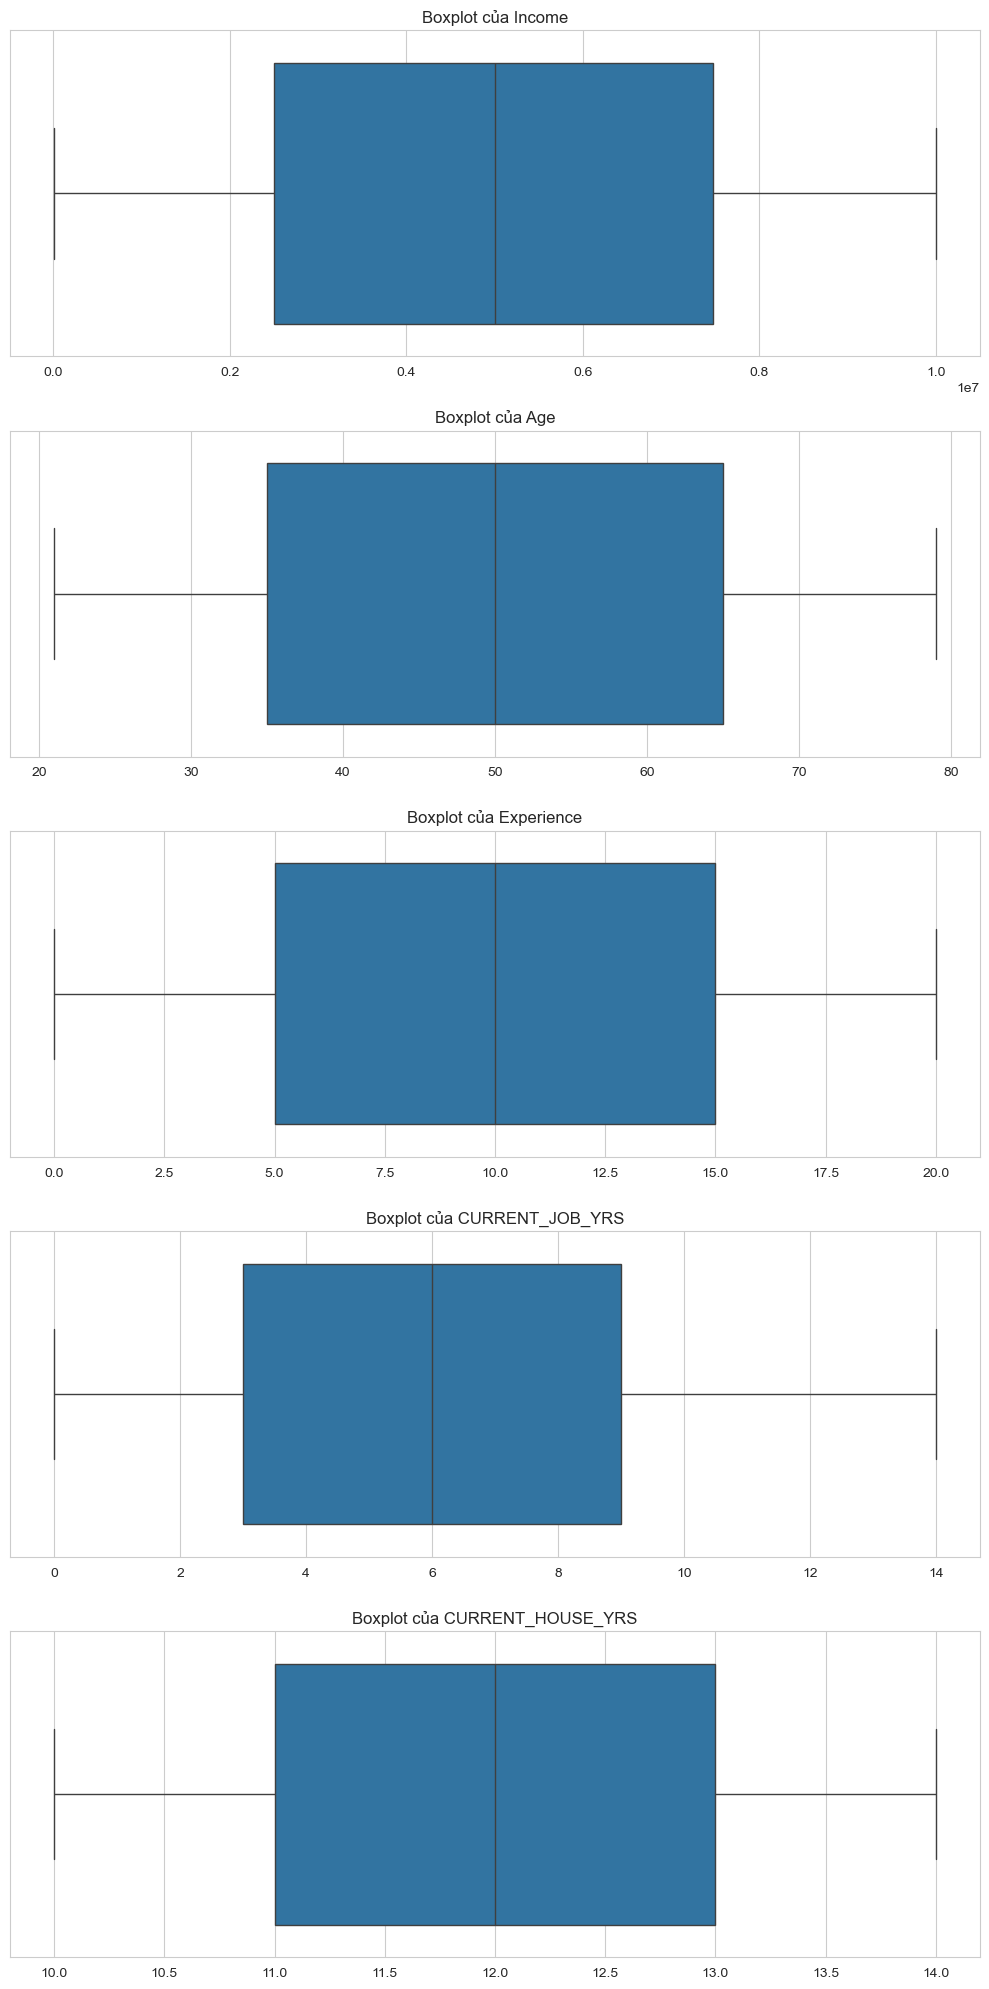


🔍 PHÁT HIỆN NGOẠI LAI (IQR)
--------------------------------------------------
Income              :        0 ngoại lai ( 0.00%)
Age                 :        0 ngoại lai ( 0.00%)
Experience          :        0 ngoại lai ( 0.00%)
CURRENT_JOB_YRS     :        0 ngoại lai ( 0.00%)
CURRENT_HOUSE_YRS   :        0 ngoại lai ( 0.00%)


In [5]:
# 1. XÁC ĐỊNH BIẾN SỐ
numerical_cols = ['Income', 'Age', 'Experience', 'CURRENT_JOB_YRS', 'CURRENT_HOUSE_YRS']

# Lọc những cột thực sự tồn tại trong df
numerical_cols = [col for col in numerical_cols if col in df.columns]

print(f"\nĐang phân tích {len(numerical_cols)} biến số:")
print(", ".join(numerical_cols))

# 2. THỐNG KÊ MÔ TẢ
print("\n📈 THỐNG KÊ MÔ TẢ")
print("-" * 80)

summary_stats = df[numerical_cols].describe().T

# IQR
summary_stats['IQR'] = summary_stats['75%'] - summary_stats['25%']

# CV (tránh chia cho 0)
summary_stats['CV'] = summary_stats['std'] / summary_stats['mean'].replace(0, 1)

# Đếm số lượng giá trị = 0
summary_stats['Zeros'] = (df[numerical_cols] == 0).sum().values

display(summary_stats[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'IQR', 'CV', 'Zeros']])

# 3. BOXPLOT (PHÁT HIỆN OUTLIER)

fig, axes = plt.subplots(len(numerical_cols), 1, figsize=(10, 4 * len(numerical_cols)))

if len(numerical_cols) == 1:
    axes = [axes]

for idx, col in enumerate(numerical_cols):
    sns.boxplot(data=df, x=col, ax=axes[idx])
    axes[idx].set_title(f'Boxplot của {col}')
    axes[idx].set_xlabel('')

plt.tight_layout()
plt.show()

# 4. PHÁT HIỆN OUTLIER (IQR)
print("\n🔍 PHÁT HIỆN NGOẠI LAI (IQR)")
print("-" * 50)

for col in numerical_cols:
    
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outlier_pct = len(outliers) / len(df) * 100
    
    print(f"{col:<20}: {len(outliers):>8,} ngoại lai ({outlier_pct:5.2f}%)")

Tổng thể, phân tích thống kê mô tả kết hợp với boxplot cho thấy dữ liệu có xu hướng phân phối cân đối về mặt trung tâm nhưng tồn tại sự khác biệt rõ rệt về mức độ phân tán giữa các biến. Cụ thể, các biến Income, Experience và CURRENT_JOB_YRS có độ biến động cao với hệ số biến thiên lần lượt là 0,576, 0,595 và 0,576, cùng với khoảng giá trị rộng như Income từ 10.310 đến 999.938, Experience từ 0 đến 20 và CURRENT_JOB_YRS từ 0 đến 14, phản ánh sự chênh lệch đáng kể giữa các cá thể và khả năng xuất hiện các giá trị ngoại lệ.

Trong khi đó, biến Age có mức biến động trung bình với độ lệch chuẩn 17,06 và hệ số biến thiên 0,342, phân phối tương đối ổn định trong khoảng từ 21 đến 79. Ngược lại, biến CURRENT_HOUSE_YRS thể hiện mức độ tập trung cao với độ lệch chuẩn 1,40, hệ số biến thiên 0,117 và khoảng giá trị hẹp từ 10 đến 14, cho thấy sự khác biệt giữa các cá thể là không đáng kể.

Như vậy, dữ liệu có sự không đồng đều về mức độ biến thiên giữa các biến, trong đó một số biến mang nhiều thông tin phân biệt nhưng cũng tiềm ẩn ngoại lệ, trong khi một số biến có tính ổn định cao. Do đó, trước khi tiến hành phân tích sâu hoặc xây dựng mô hình, cần xem xét xử lý giá trị ngoại lai, chuẩn hóa dữ liệu và đánh giá lại vai trò của các biến có phương sai thấp.


#### Phân phối của biến mục tiêu Risk_Flag

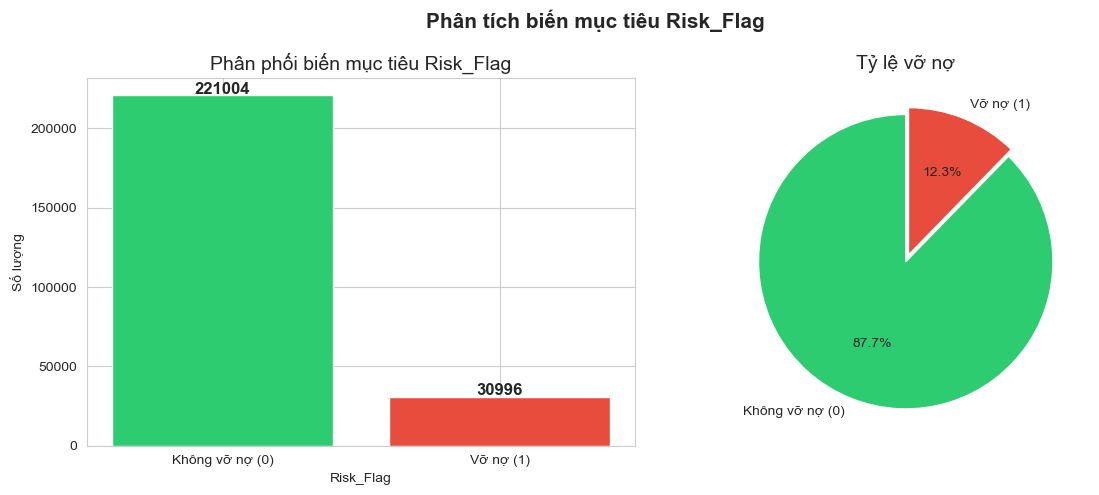

Số lượng không vỡ nợ (0): 221,004
Số lượng vỡ nợ (1): 30,996
Tỷ lệ vỡ nợ: 12.30%
Tỷ lệ không vỡ nợ: 87.70%


In [6]:
#Phân phối của biến mục tiêu Risk_Flag
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# Biểu đồ cột
risk_counts = df['Risk_Flag'].value_counts()
axes[0].bar(['Không vỡ nợ (0)', 'Vỡ nợ (1)'], risk_counts.values, color=['#2ecc71', '#e74c3c'])
axes[0].set_title('Phân phối biến mục tiêu Risk_Flag', fontsize=14)
axes[0].set_ylabel('Số lượng')
axes[0].set_xlabel('Risk_Flag')
for i, v in enumerate(risk_counts.values):
    axes[0].text(i, v + 1000, str(v), ha='center', fontweight='bold', fontsize=12)

# Biểu đồ tròn
axes[1].pie(risk_counts.values, labels=['Không vỡ nợ (0)', 'Vỡ nợ (1)'],
            autopct='%1.1f%%', colors=['#2ecc71', '#e74c3c'], startangle=90,
            explode=(0, 0.05))
axes[1].set_title('Tỷ lệ vỡ nợ', fontsize=14)

plt.suptitle('Phân tích biến mục tiêu Risk_Flag', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Số lượng không vỡ nợ (0): {risk_counts[0]:,}")
print(f"Số lượng vỡ nợ (1): {risk_counts[1]:,}")
print(f"Tỷ lệ vỡ nợ: {df['Risk_Flag'].mean()*100:.2f}%")
print(f"Tỷ lệ không vỡ nợ: {(1-df['Risk_Flag'].mean())*100:.2f}%")

#### Phân Phối Các Biến Số Theo Risk_Flag (Biến mục tiêu)

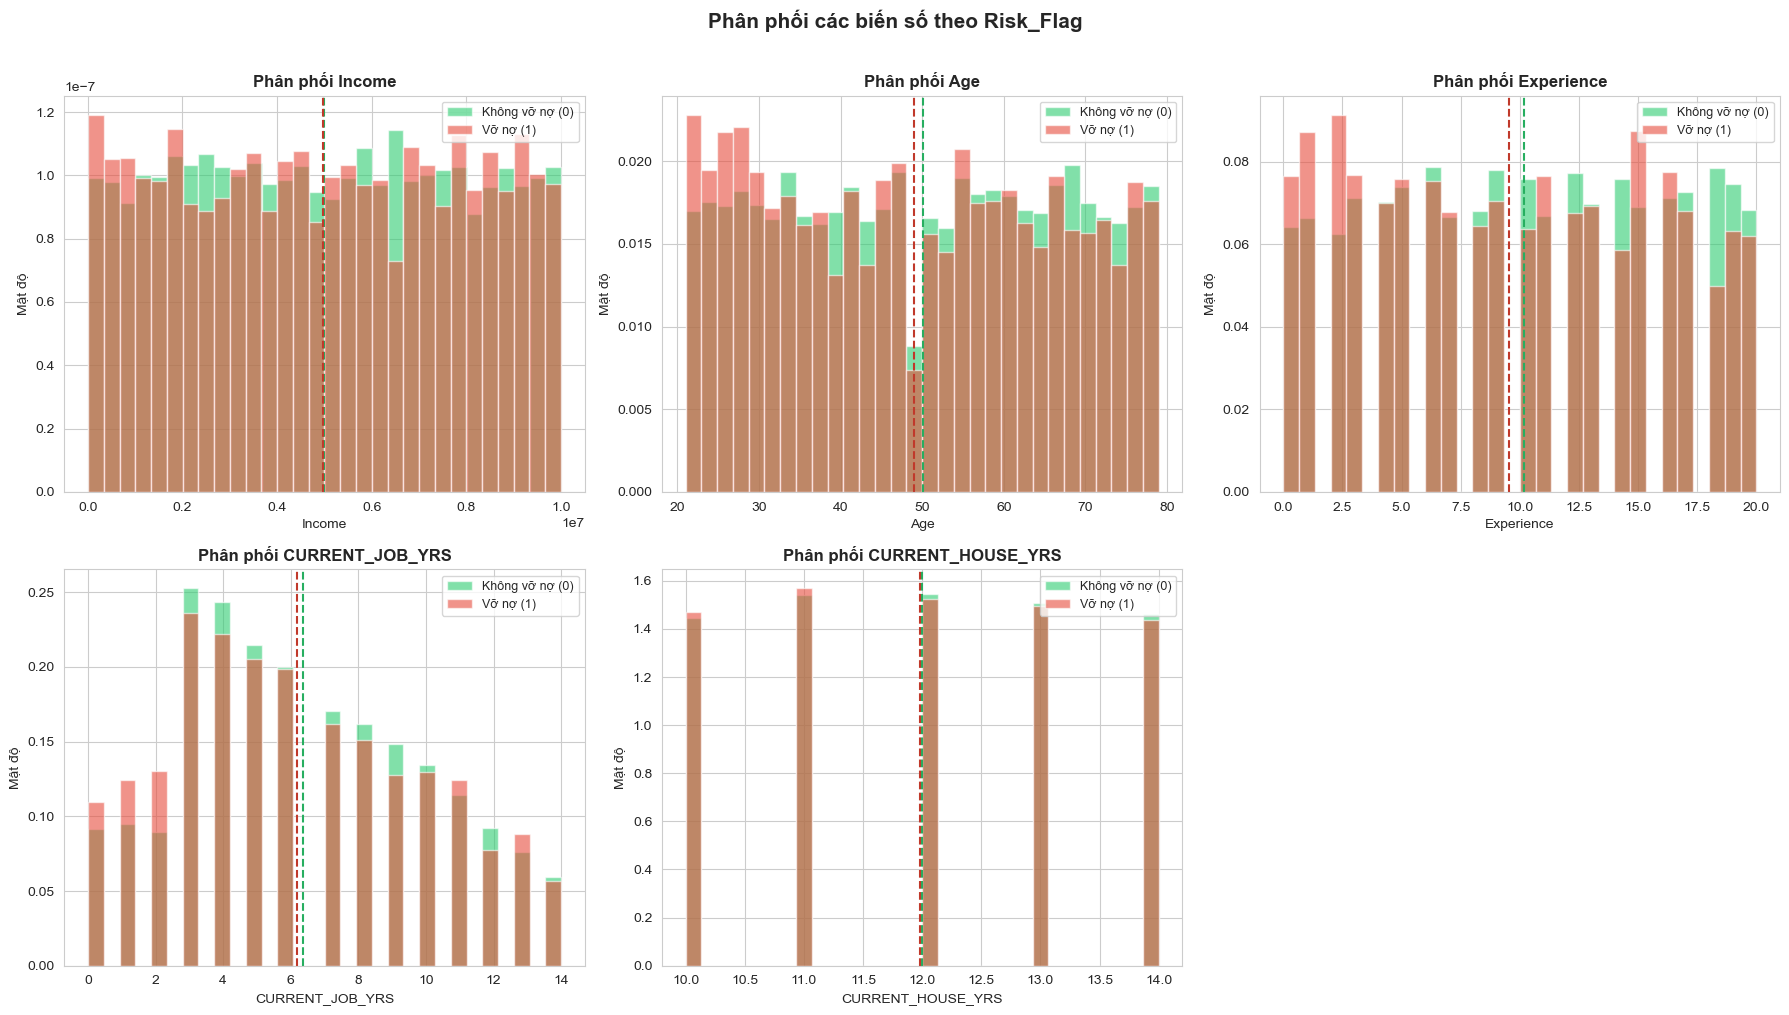

Thống kê trung bình theo nhóm Risk_Flag:
               Income    Age  Experience  CURRENT_JOB_YRS  CURRENT_HOUSE_YRS
Risk_Flag                                                                   
0          5000448.72  50.09       10.16             6.36              12.00
1          4973358.84  48.96        9.53             6.17              11.98


In [7]:
#Phân Phối Các Biến Số Theo Nhóm Risk_Flag
numeric_features = ['Income', 'Age', 'Experience', 'CURRENT_JOB_YRS', 'CURRENT_HOUSE_YRS']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(numeric_features):
    for flag, color, label in [(0, '#2ecc71', 'Không vỡ nợ (0)'), (1, '#e74c3c', 'Vỡ nợ (1)')]:
        axes[i].hist(df[df['Risk_Flag'] == flag][col], bins=30, alpha=0.6,
                     color=color, label=label, density=True)
    axes[i].set_title(f'Phân phối {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Mật độ', fontsize=10)
    axes[i].legend(fontsize=9)

    # Thêm đường trung bình
    mean0 = df[df['Risk_Flag'] == 0][col].mean()
    mean1 = df[df['Risk_Flag'] == 1][col].mean()
    axes[i].axvline(mean0, color='#27ae60', linestyle='--', linewidth=1.5,
                    label=f'TB không vỡ nợ: {mean0:.1f}')
    axes[i].axvline(mean1, color='#c0392b', linestyle='--', linewidth=1.5,
                    label=f'TB vỡ nợ: {mean1:.1f}')

axes[5].set_visible(False)



plt.suptitle('Phân phối các biến số theo Risk_Flag', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print("Thống kê trung bình theo nhóm Risk_Flag:")
print(df.groupby('Risk_Flag')[numeric_features].mean().round(2))

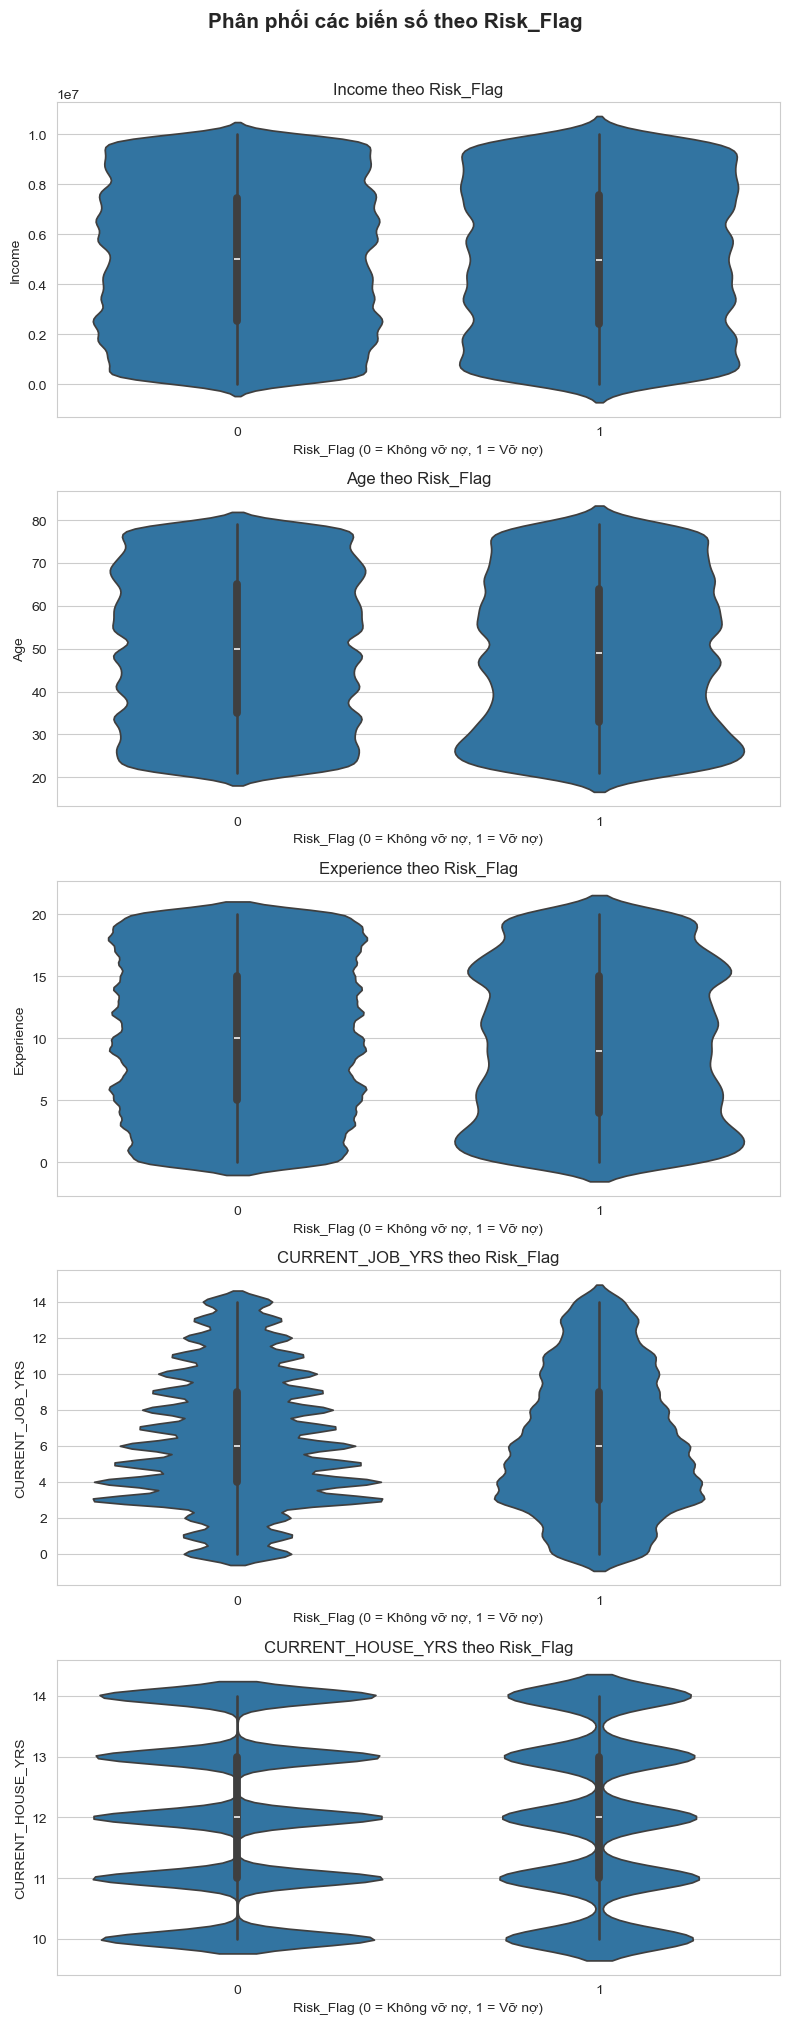

In [8]:
# Vẽ violin plot cho từng biến
fig, axes = plt.subplots(len(numeric_features), 1, figsize=(8, 4 * len(numeric_features)))

if len(numeric_features) == 1:
    axes = [axes]

for i, col in enumerate(numeric_features):
    sns.violinplot(data=df, x='Risk_Flag', y=col, ax=axes[i])
    axes[i].set_title(f'{col} theo Risk_Flag')
    axes[i].set_xlabel('Risk_Flag (0 = Không vỡ nợ, 1 = Vỡ nợ)')
plt.suptitle('Phân phối các biến số theo Risk_Flag', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

#### Phân Phối Các Biến Phân Loại

📊 PHÂN TÍCH ĐƠN BIẾN: BIẾN PHÂN LOẠI

Đang phân tích 6 biến phân loại:

Married/Single:
  Số nhóm: 2
  Top 3: {'single': 226272, 'married': 25728}
  Phổ biến nhất: single (89.79%)

House_Ownership:
  Số nhóm: 3
  Top 3: {'rented': 231898, 'owned': 12918, 'norent_noown': 7184}
  Phổ biến nhất: rented (92.02%)

Car_Ownership:
  Số nhóm: 2
  Top 3: {'no': 176000, 'yes': 76000}
  Phổ biến nhất: no (69.84%)

Profession:
  Số nhóm: 51
  Top 3: {'Physician': 5957, 'Statistician': 5806, 'Web_designer': 5397}
  Phổ biến nhất: Physician (2.36%)

CITY:
  Số nhóm: 317
  Top 3: {'Vijayanagaram': 1259, 'Bhopal': 1208, 'Bulandshahr': 1185}
  Phổ biến nhất: Vijayanagaram (0.50%)

STATE:
  Số nhóm: 29
  Top 3: {'Uttar_Pradesh': 28400, 'Maharashtra': 25562, 'Andhra_Pradesh': 25297}
  Phổ biến nhất: Uttar_Pradesh (11.27%)


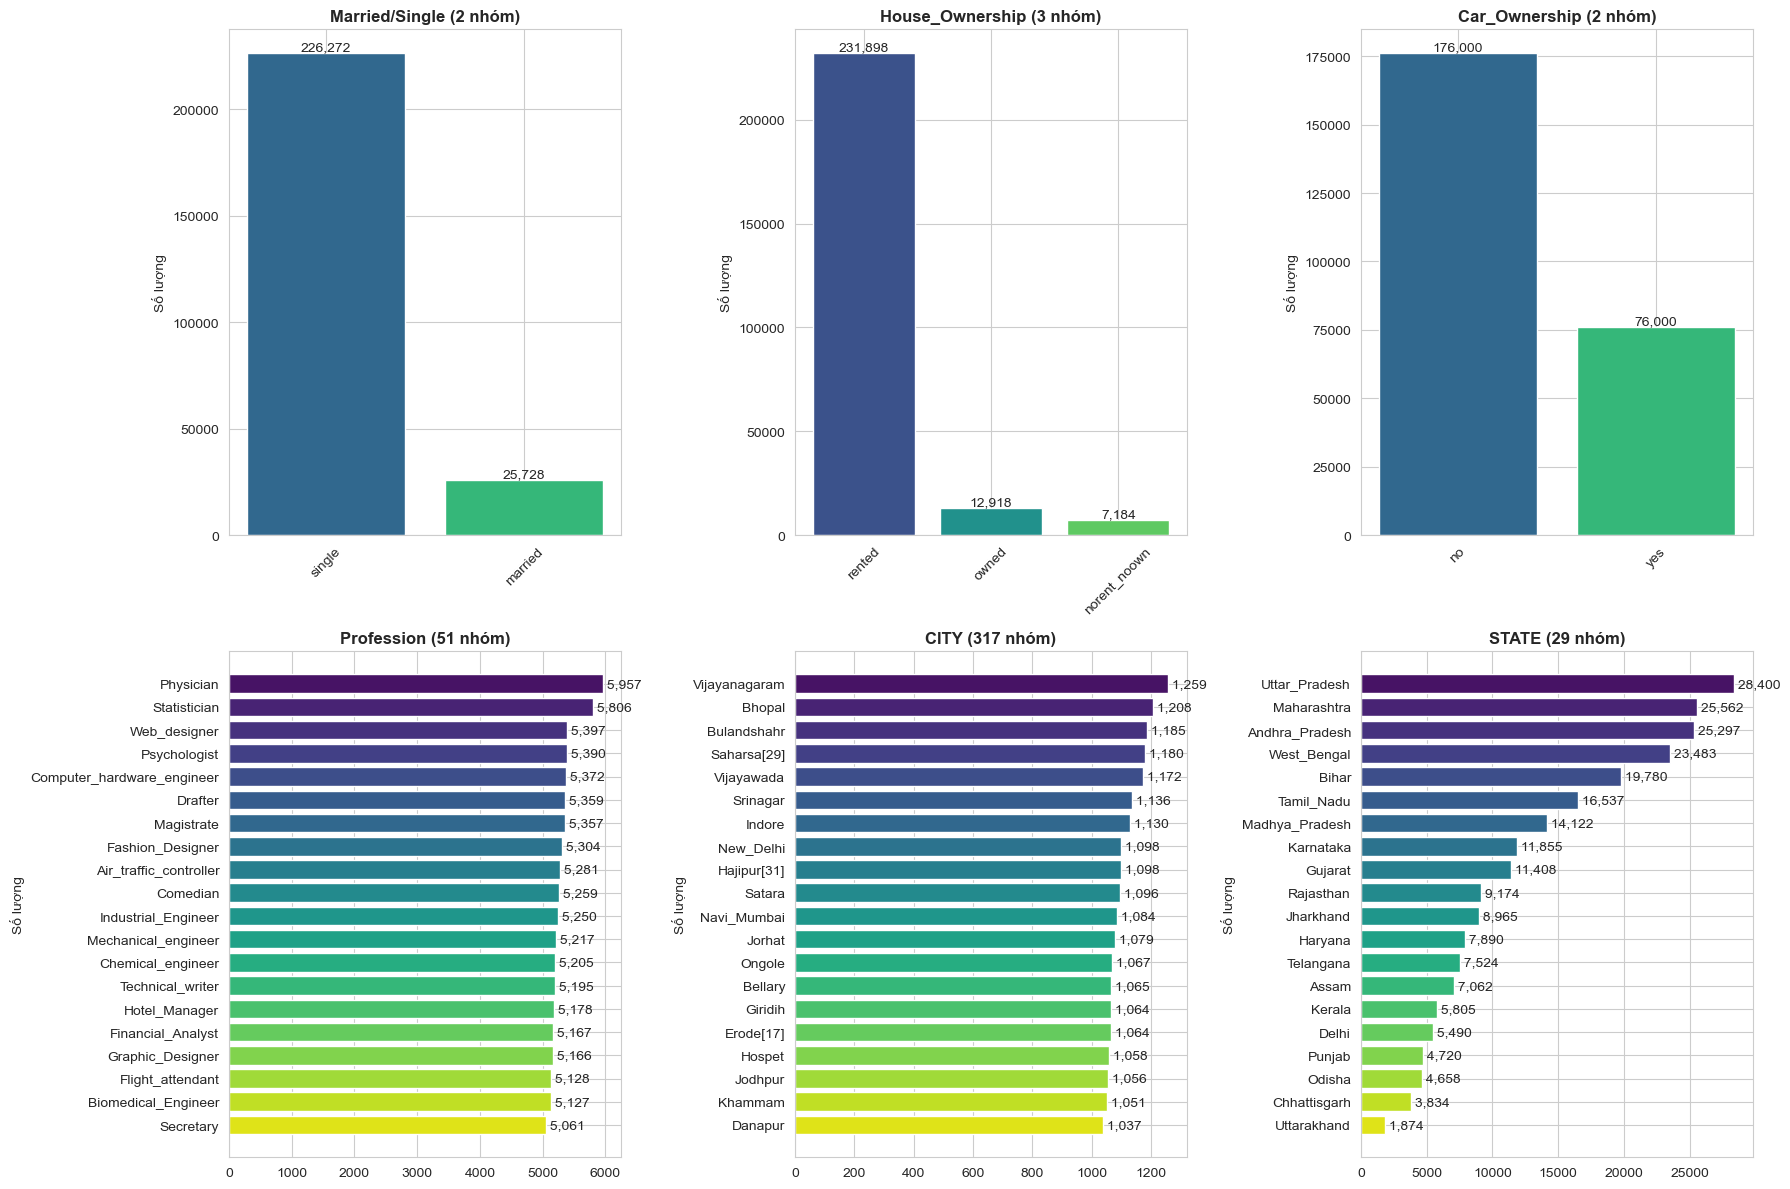

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

print("📊 PHÂN TÍCH ĐƠN BIẾN: BIẾN PHÂN LOẠI")
print("=" * 60)

categorical_cols = ['Married/Single', 'House_Ownership', 'Car_Ownership', 
                    'Profession', 'CITY', 'STATE']

# Lọc cột tồn tại
categorical_cols = [col for col in categorical_cols if col in df.columns]

print(f"\nĐang phân tích {len(categorical_cols)} biến phân loại:")

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, col in enumerate(categorical_cols):
    
    value_counts = df[col].value_counts()
    
    # 🔹 Tạo bảng màu gradient
    colors = sns.color_palette("viridis", len(value_counts) if len(value_counts) <= 20 else 20)
    
    if len(value_counts) > 20:
        top_data = value_counts.head(20)
        
        bars = axes[idx].barh(top_data.index, top_data.values, color=colors)
        axes[idx].invert_yaxis()
        
        for i, v in enumerate(top_data.values):
            axes[idx].text(v, i, f' {v:,}', va='center')
    
    else:
        bars = axes[idx].bar(value_counts.index, value_counts.values, color=colors)
        axes[idx].tick_params(axis='x', rotation=45)
        
        for i, v in enumerate(value_counts.values):
            axes[idx].text(i, v, f'{v:,}', ha='center', va='bottom')
    
    axes[idx].set_title(f'{col} ({len(value_counts)} nhóm)', fontweight='bold')
    axes[idx].set_ylabel('Số lượng')

    # 📌 In thống kê
    print(f"\n{col}:")
    print(f"  Số nhóm: {len(value_counts)}")
    print(f"  Top 3: {value_counts.head(3).to_dict()}")
    print(f"  Phổ biến nhất: {value_counts.index[0]} ({value_counts.iloc[0]/len(df):.2%})")

# Ẩn subplot dư
for j in range(len(categorical_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

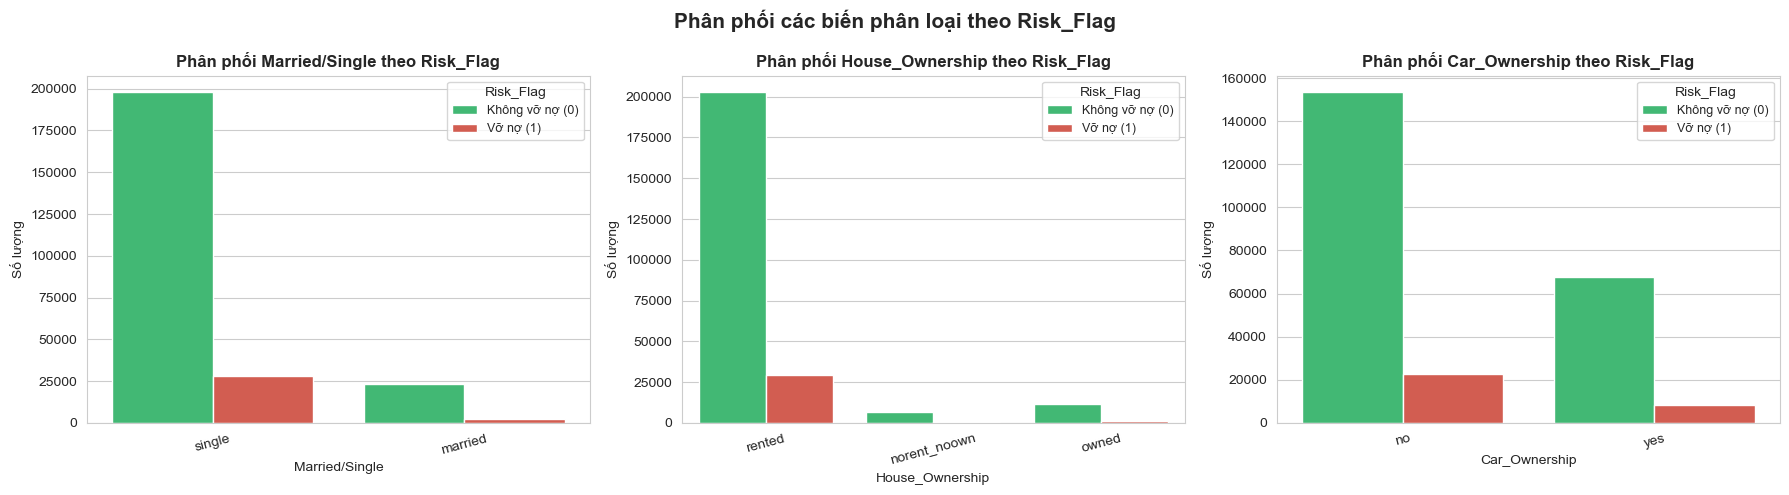

In [10]:
#Phân Phối Các Biến Phân Loại Theo Risk_Flag
cat_features = ['Married/Single', 'House_Ownership', 'Car_Ownership']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(cat_features):
    sns.countplot(data=df, x=col, hue='Risk_Flag', ax=axes[i],
                  palette={0: '#2ecc71', 1: '#e74c3c'})
    axes[i].set_title(f'Phân phối {col} theo Risk_Flag', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Số lượng', fontsize=10)
    handles, _ = axes[i].get_legend_handles_labels()
    axes[i].legend(handles, ['Không vỡ nợ (0)', 'Vỡ nợ (1)'], title='Risk_Flag', fontsize=9)
    axes[i].tick_params(axis='x', rotation=15)

plt.suptitle('Phân phối các biến phân loại theo Risk_Flag', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

#### Tỷ Lệ Vỡ Nợ Theo Các Biến Phân Loại

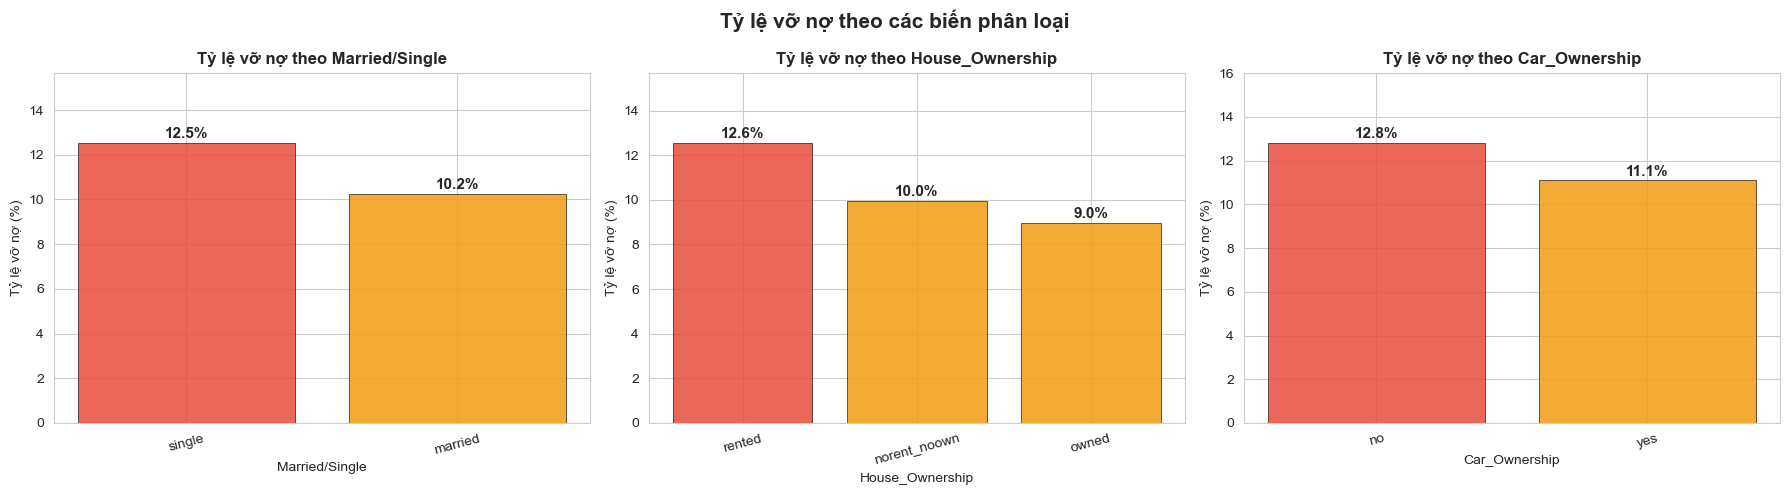

Chi tiết tỷ lệ vỡ nợ theo từng nhóm:

--- Married/Single ---
Married/Single
married    10.25
single     12.53

--- House_Ownership ---
House_Ownership
norent_noown     9.95
owned            8.98
rented          12.56

--- Car_Ownership ---
Car_Ownership
no     12.82
yes    11.10


In [11]:
cat_features = ['Married/Single', 'House_Ownership', 'Car_Ownership']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(cat_features):
    risk_rate = df.groupby(col)['Risk_Flag'].mean() * 100
    risk_rate = risk_rate.sort_values(ascending=False)
    colors_list = ['#e74c3c' if v >= 12 else '#f39c12' if v >= 8 else '#2ecc71'
                   for v in risk_rate.values]
    bars = axes[i].bar(range(len(risk_rate)), risk_rate.values,
                       color=colors_list, alpha=0.85, edgecolor='black', linewidth=0.5)
    axes[i].set_title(f'Tỷ lệ vỡ nợ theo {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Tỷ lệ vỡ nợ (%)', fontsize=10)
    axes[i].set_xticks(range(len(risk_rate)))
    axes[i].set_xticklabels(risk_rate.index, rotation=15)
    axes[i].set_ylim(0, risk_rate.max() * 1.25)
    for j, val in enumerate(risk_rate.values):
        axes[i].text(j, val + 0.2, f'{val:.1f}%', ha='center', fontweight='bold', fontsize=11)

plt.suptitle('Tỷ lệ vỡ nợ theo các biến phân loại', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

print("Chi tiết tỷ lệ vỡ nợ theo từng nhóm:")
for col in cat_features:
    print(f"\n--- {col} ---")
    print((df.groupby(col)['Risk_Flag'].mean() * 100).round(2).to_string())

##### Ma trận tương quan giữa các biến số

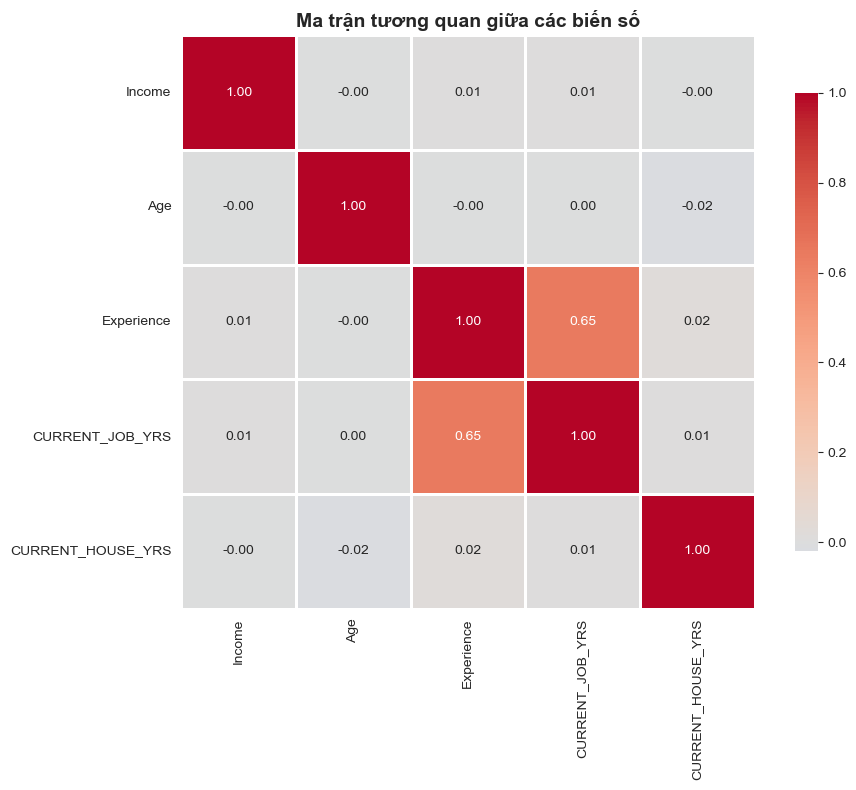

In [12]:
# 1. TÍNH MA TRẬN TƯƠNG QUAN
# Lọc các cột số thực sự tồn tại trong df
numerical_cols = [col for col in numerical_cols if col in df.columns]

# Tính hệ số tương quan Pearson
correlation_matrix = df[numerical_cols].corr()

# 2. VẼ HEATMAP
plt.figure(figsize=(10, 8))

heatmap = sns.heatmap(
    correlation_matrix,
    annot=True,          
    fmt='.2f',           # Làm tròn 2 chữ số
    cmap='coolwarm',     # Màu: đỏ (dương) - xanh (âm)
    center=0,            # Tâm tại 0
    square=True,         
    linewidths=1,        
    cbar_kws={"shrink": 0.8}  
)

plt.title('Ma trận tương quan giữa các biến số', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Nhận Xét:

**Nhận xét về phân phối biến mục tiêu và mất cân bằng lớp:**

Kết quả phân tích cho thấy tập dữ liệu có sự mất cân bằng lớp (class imbalance) rõ rệt: tỷ lệ khách hàng vỡ nợ (Risk_Flag = 1) chỉ chiếm khoảng 12% tổng tập dữ liệu, trong khi nhóm không vỡ nợ (Risk_Flag = 0) chiếm khoảng 88%. Đây là tình trạng phổ biến trong các bài toán phát hiện rủi ro tín dụng thực tế, phản ánh đúng thực trạng rằng đa số người vay đều trả nợ đúng hạn. Sự mất cân bằng này đặt ra thách thức lớn cho các thuật toán học máy: nếu không xử lý, mô hình có xu hướng thiên vị về lớp đa số (không vỡ nợ), dẫn đến độ chính xác tổng thể cao nhưng khả năng phát hiện các trường hợp vỡ nợ (nhóm thiểu số) lại rất kém – đây chính là nhóm cần được dự báo chính xác nhất trong quản lý rủi ro tín dụng. Vì vậy, kỹ thuật SMOTE sẽ được áp dụng để cân bằng lại tỉ lệ giữa hai nhóm.

**Nhận xét về các biến số và mối quan hệ với biến mục tiêu:**

Qua phân tích phân phối các biến số, có thể nhận thấy rằng **thu nhập (Income)** và **kinh nghiệm làm việc (Experience)** là hai biến thể hiện sự khác biệt rõ rệt nhất giữa nhóm vỡ nợ và không vỡ nợ. Khách hàng vỡ nợ có xu hướng có thu nhập thấp hơn và ít kinh nghiệm làm việc hơn so với nhóm không vỡ nợ. Biến **Age** (tuổi) cũng có sự phân biệt nhất định, với khách hàng vỡ nợ thường ở nhóm tuổi trẻ hơn. Đáng chú ý, biến **CURRENT_JOB_YRS** (số năm làm việc tại công việc hiện tại) cho thấy khách hàng có thời gian làm việc ngắn hơn tại một vị trí có tỷ lệ vỡ nợ cao hơn, phản ánh sự không ổn định về nguồn thu nhập. Ma trận tương quan xác nhận rằng các biến số không có hiện tượng đa cộng tuyến nghiêm trọng, đảm bảo tính tin cậy của các mô hình học máy được xây dựng.

**Nhận xét về các biến phân loại:**

Phân tích các biến phân loại cho thấy **tình trạng sở hữu nhà (House_Ownership)** là yếu tố có tác động rõ rệt nhất đến tỷ lệ vỡ nợ: nhóm khách hàng đang **thuê nhà (rented)** có tỷ lệ vỡ nợ cao hơn đáng kể so với nhóm sở hữu nhà (owned) hoặc không có nhà cố định, phản ánh mức độ ổn định tài chính và tài sản thế chấp tiềm năng của khách hàng. Về **tình trạng hôn nhân (Married/Single)**, khách hàng đã kết hôn có tỷ lệ vỡ nợ thấp hơn nhẹ so với khách hàng độc thân, điều này có thể được lý giải qua sự chia sẻ trách nhiệm tài chính trong gia đình. Biến **Car_Ownership** cũng thể hiện xu hướng tương tự khi khách hàng có xe thường có tỷ lệ vỡ nợ thấp hơn, phản ánh khả năng tích lũy tài sản tốt hơn.

#### 3. Quy trình tiền xử lý dữ liệu

In [13]:
# Loại bỏ các cột có cardinality cao (Profession, CITY, STATE) và Id
df_model = df.drop(['Id', 'CITY', 'STATE', 'Profession'], axis=1)
print("Các cột sau khi loại bỏ:")
print(list(df_model.columns))

# Mã hóa biến phân loại bằng Label Encoding
le = LabelEncoder()
df_model['Married/Single'] = le.fit_transform(df_model['Married/Single'])
print(f"\nMarried/Single: {dict(zip(le.classes_, le.transform(le.classes_)))}")

df_model['House_Ownership'] = le.fit_transform(df_model['House_Ownership'])
print(f"House_Ownership: {dict(zip(le.classes_, le.transform(le.classes_)))}")

df_model['Car_Ownership'] = le.fit_transform(df_model['Car_Ownership'])
print(f"Car_Ownership: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# Tách biến đầu vào và biến mục tiêu
X = df_model.drop('Risk_Flag', axis=1)
y = df_model['Risk_Flag']

print(f"\nSố chiều của X: {X.shape}")
print(f"Số chiều của y: {y.shape}")

# Phân chia tập train/test (80/20, stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nTập huấn luyện (trước SMOTE): {X_train.shape[0]:,} mẫu")
print(f"Tập kiểm tra: {X_test.shape[0]:,} mẫu")

# Chuẩn hóa biến số
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Áp dụng SMOTE để xử lý mất cân bằng lớp
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

print(f"\nTrước SMOTE: {dict(zip(*np.unique(y_train, return_counts=True)))}")
print(f"Sau SMOTE: {dict(zip(*np.unique(y_train_res, return_counts=True)))}")
print(f"\nTập huấn luyện sau SMOTE: {X_train_res.shape[0]:,} mẫu")
print(f"Tập kiểm tra: {X_test_scaled.shape[0]:,} mẫu")

Các cột sau khi loại bỏ:
['Income', 'Age', 'Experience', 'Married/Single', 'House_Ownership', 'Car_Ownership', 'CURRENT_JOB_YRS', 'CURRENT_HOUSE_YRS', 'Risk_Flag']

Married/Single: {'married': 0, 'single': 1}
House_Ownership: {'norent_noown': 0, 'owned': 1, 'rented': 2}
Car_Ownership: {'no': 0, 'yes': 1}

Số chiều của X: (252000, 8)
Số chiều của y: (252000,)

Tập huấn luyện (trước SMOTE): 201,600 mẫu
Tập kiểm tra: 50,400 mẫu

Trước SMOTE: {0: 176803, 1: 24797}
Sau SMOTE: {0: 176803, 1: 176803}

Tập huấn luyện sau SMOTE: 353,606 mẫu
Tập kiểm tra: 50,400 mẫu


#### 4. Lựa Chọn Mô Hình, Huấn Luyện và Đánh Giá Mô Hình

Trong phần này, bốn mô hình học máy được huấn luyện và đánh giá:

1. **Logistic Regression** – Mô hình tuyến tính, đơn giản, dễ giải thích, thường được dùng làm baseline trong các bài toán phân loại nhị phân.
2. **Decision Tree** – Mô hình cây quyết định, trực quan, có thể nắm bắt các quan hệ phi tuyến, nhưng dễ bị overfitting.
3. **Random Forest** – Mô hình ensemble sử dụng kỹ thuật bagging với nhiều cây quyết định, cho kết quả ổn định và ít bị overfitting hơn.
4. **XGBoost** – Mô hình gradient boosting tối ưu hóa bậc hai, thường cho hiệu suất cao nhất trong các cuộc thi học máy với dữ liệu dạng bảng.

In [14]:
results = {}

def evaluate_model(name, model, X_train, y_train, X_test, y_test):
    """Huấn luyện mô hình, tính toán và hiển thị các chỉ số đánh giá."""
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec  = recall_score(y_test, y_pred)
    f1   = f1_score(y_test, y_pred)
    auc  = roc_auc_score(y_test, y_prob)

    results[name] = {
        'model': model, 'y_pred': y_pred, 'y_prob': y_prob,
        'Accuracy': acc, 'Precision': prec, 'Recall': rec,
        'F1-Score': f1, 'AUC-ROC': auc
    }

    print(f"{'='*60}")
    print(f"MÔ HÌNH: {name}")
    print(f"{'='*60}")
    print(f"  Accuracy : {acc:.4f}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall   : {rec:.4f}")
    print(f"  F1-Score : {f1:.4f}")
    print(f"  AUC-ROC  : {auc:.4f}")
    print(f"\nBáo cáo phân loại chi tiết:")
    print(classification_report(y_test, y_pred, target_names=['Không vỡ nợ', 'Vỡ nợ']))

    # Ma trận nhầm lẫn
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Không vỡ nợ', 'Vỡ nợ'],
                yticklabels=['Không vỡ nợ', 'Vỡ nợ'],
                annot_kws={'size': 13})
    plt.title(f'Ma trận nhầm lẫn – {name}', fontsize=13, fontweight='bold')
    plt.ylabel('Thực tế', fontsize=11)
    plt.xlabel('Dự đoán', fontsize=11)
    plt.tight_layout()
    plt.show()

    return model

#### 4.1 Mô Hình Logistic Regression

MÔ HÌNH: Logistic Regression
  Accuracy : 0.5127
  Precision: 0.1367
  Recall   : 0.5570
  F1-Score : 0.2195
  AUC-ROC  : 0.5463

Báo cáo phân loại chi tiết:
              precision    recall  f1-score   support

 Không vỡ nợ       0.89      0.51      0.65     44201
       Vỡ nợ       0.14      0.56      0.22      6199

    accuracy                           0.51     50400
   macro avg       0.51      0.53      0.43     50400
weighted avg       0.80      0.51      0.59     50400



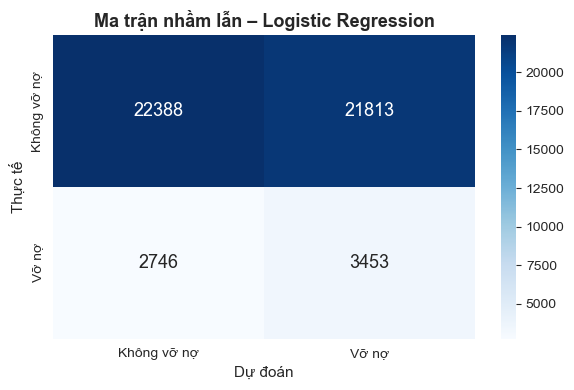

In [15]:
lr_model = evaluate_model(
    'Logistic Regression',
    LogisticRegression(max_iter=1000, random_state=42),
    X_train_res, y_train_res,
    X_test_scaled, y_test
)

#### 4.2 Mô Hình Decision Tree

MÔ HÌNH: Decision Tree
  Accuracy : 0.7289
  Precision: 0.2032
  Recall   : 0.4122
  F1-Score : 0.2722
  AUC-ROC  : 0.6471

Báo cáo phân loại chi tiết:
              precision    recall  f1-score   support

 Không vỡ nợ       0.90      0.77      0.83     44201
       Vỡ nợ       0.20      0.41      0.27      6199

    accuracy                           0.73     50400
   macro avg       0.55      0.59      0.55     50400
weighted avg       0.82      0.73      0.76     50400



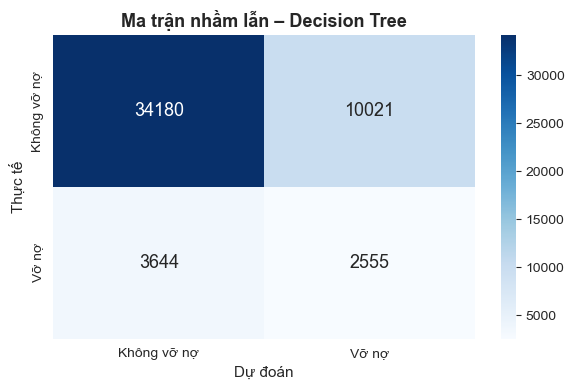

In [16]:
dt_model = evaluate_model(
    'Decision Tree',
    DecisionTreeClassifier(max_depth=10, random_state=42),
    X_train_res, y_train_res,
    X_test_scaled, y_test
)

#### 4.3 Mô Hình Random Forest

MÔ HÌNH: Random Forest
  Accuracy : 0.8601
  Precision: 0.4573
  Recall   : 0.7366
  F1-Score : 0.5643
  AUC-ROC  : 0.8720

Báo cáo phân loại chi tiết:
              precision    recall  f1-score   support

 Không vỡ nợ       0.96      0.88      0.92     44201
       Vỡ nợ       0.46      0.74      0.56      6199

    accuracy                           0.86     50400
   macro avg       0.71      0.81      0.74     50400
weighted avg       0.90      0.86      0.87     50400



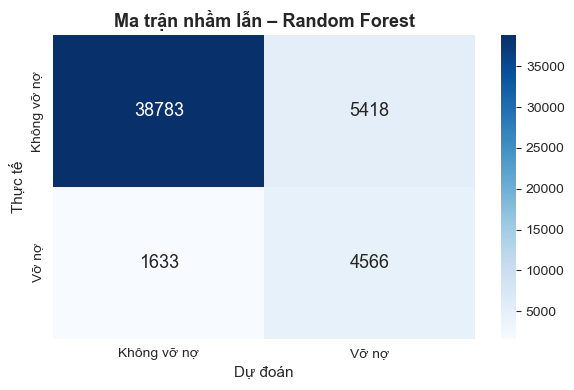

In [17]:
rf_model = evaluate_model(
    'Random Forest',
    RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1),
    X_train_res, y_train_res,
    X_test_scaled, y_test
)

#### 4.4 Mô Hình XGBoost

MÔ HÌNH: XGBoost
  Accuracy : 0.7684
  Precision: 0.2975
  Recall   : 0.6487
  F1-Score : 0.4079
  AUC-ROC  : 0.7899

Báo cáo phân loại chi tiết:
              precision    recall  f1-score   support

 Không vỡ nợ       0.94      0.79      0.86     44201
       Vỡ nợ       0.30      0.65      0.41      6199

    accuracy                           0.77     50400
   macro avg       0.62      0.72      0.63     50400
weighted avg       0.86      0.77      0.80     50400



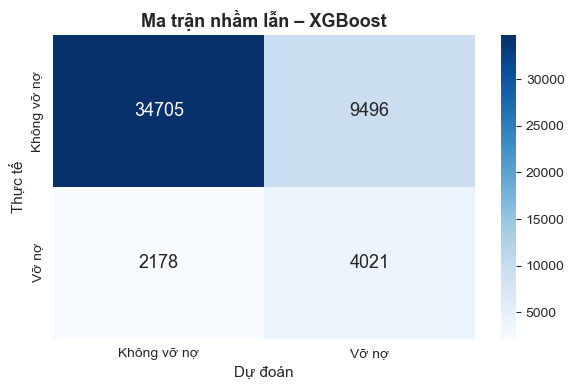

In [18]:
xgb_model = evaluate_model(
    'XGBoost',
    XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1,
                  random_state=42, eval_metric='logloss'),
    X_train_res, y_train_res,
    X_test_scaled, y_test
)

### Bảng So Sánh Hiệu Suất Các Mô Hình

In [19]:
comparison_df = pd.DataFrame(
    {name: {k: v for k, v in vals.items() if k not in ['model', 'y_pred', 'y_prob']}
     for name, vals in results.items()}
).T

comparison_df = comparison_df.sort_values('AUC-ROC', ascending=False)
comparison_df = comparison_df.astype(float)

print("BẢNG SO SÁNH HIỆU SUẤT CÁC MÔ HÌNH")
print("="*70)
print(comparison_df.round(4).to_string())

# Highlight best values
print("\nMô hình tốt nhất theo từng chỉ số:")
for col in comparison_df.columns:
    best_model = comparison_df[col].idxmax()
    best_val = comparison_df[col].max()
    print(f"  {col:12s}: {best_model} ({best_val:.4f})")

BẢNG SO SÁNH HIỆU SUẤT CÁC MÔ HÌNH
                     Accuracy  Precision  Recall  F1-Score  AUC-ROC
Random Forest          0.8601     0.4573  0.7366    0.5643   0.8720
XGBoost                0.7684     0.2975  0.6487    0.4079   0.7899
Decision Tree          0.7289     0.2032  0.4122    0.2722   0.6471
Logistic Regression    0.5127     0.1367  0.5570    0.2195   0.5463

Mô hình tốt nhất theo từng chỉ số:
  Accuracy    : Random Forest (0.8601)
  Precision   : Random Forest (0.4573)
  Recall      : Random Forest (0.7366)
  F1-Score    : Random Forest (0.5643)
  AUC-ROC     : Random Forest (0.8720)


#### Biểu Đồ So Sánh Hiệu Suất và Đường Cong ROC

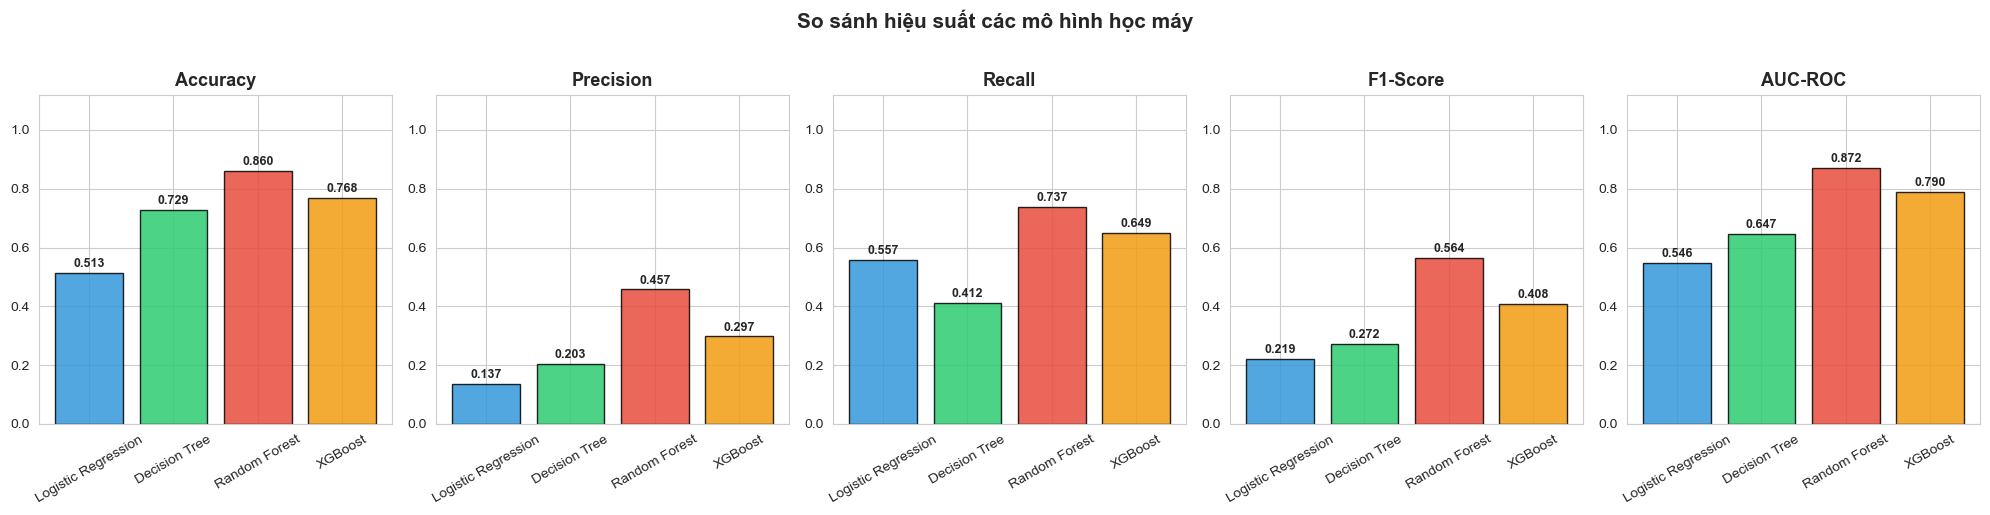

In [20]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
colors = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12']

for i, metric in enumerate(metrics):
    values = [results[name][metric] for name in results]
    bars = axes[i].bar(list(results.keys()), values, color=colors, alpha=0.85, edgecolor='black')
    axes[i].set_title(metric, fontsize=13, fontweight='bold')
    axes[i].set_ylim(0, 1.12)
    axes[i].tick_params(axis='x', rotation=30)
    for bar, val in zip(bars, values):
        axes[i].text(bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.01,
                     f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.suptitle('So sánh hiệu suất các mô hình học máy', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

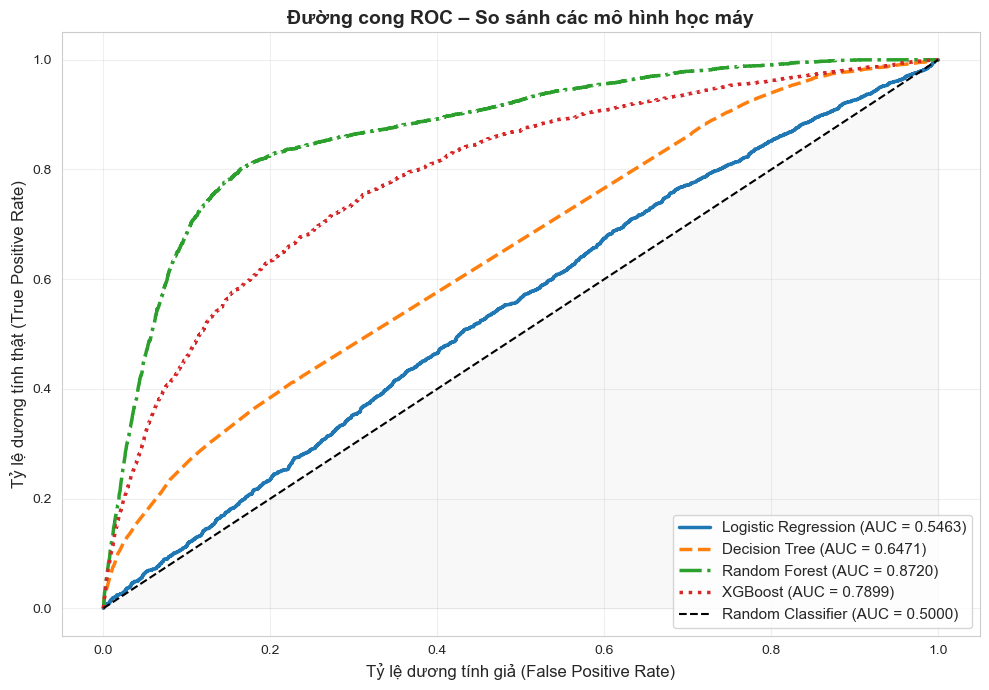

In [21]:
plt.figure(figsize=(10, 7))
line_styles = ['-', '--', '-.', ':']

for idx, (name, vals) in enumerate(results.items()):
    fpr, tpr, _ = roc_curve(y_test, vals['y_prob'])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {vals['AUC-ROC']:.4f})",
             linewidth=2.5, linestyle=line_styles[idx])

plt.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Classifier (AUC = 0.5000)')
plt.fill_between([0, 1], [0, 1], alpha=0.05, color='gray')
plt.xlabel('Tỷ lệ dương tính giả (False Positive Rate)', fontsize=12)
plt.ylabel('Tỷ lệ dương tính thật (True Positive Rate)', fontsize=12)
plt.title('Đường cong ROC – So sánh các mô hình học máy', fontsize=14, fontweight='bold')
plt.legend(fontsize=11, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### 5. Mức Độ Quan Trọng của Đặc Trưng (Random Forest)

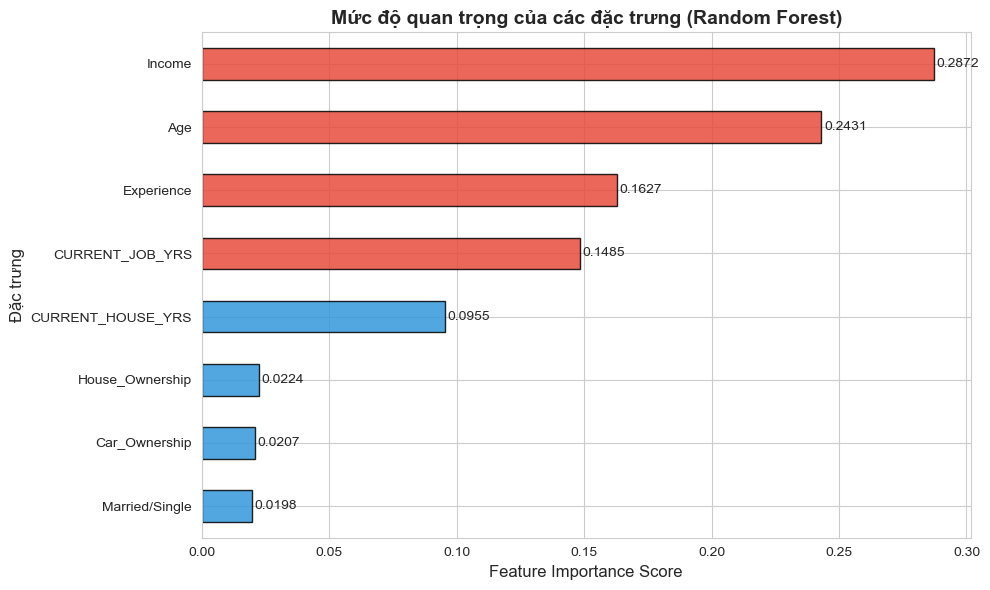


Bảng mức độ quan trọng đặc trưng (sắp xếp giảm dần):
Income               0.287246
Age                  0.243103
Experience           0.162743
CURRENT_JOB_YRS      0.148473
CURRENT_HOUSE_YRS    0.095495
House_Ownership      0.022434
Car_Ownership        0.020739
Married/Single       0.019766

Mức độ quan trọng đặc trưng theo XGBoost:
CURRENT_JOB_YRS      0.213186
Age                  0.141502
Income               0.138486
Experience           0.122373
CURRENT_HOUSE_YRS    0.099349
Car_Ownership        0.098066
House_Ownership      0.097461
Married/Single       0.089577


In [22]:
feature_names = X.columns
importances = rf_model.feature_importances_
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
colors_imp = ['#e74c3c' if v >= feat_imp.median() else '#3498db' for v in feat_imp.values]
feat_imp.plot(kind='barh', color=colors_imp, ax=ax, edgecolor='black', alpha=0.85)
ax.set_title('Mức độ quan trọng của các đặc trưng (Random Forest)',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Feature Importance Score', fontsize=12)
ax.set_ylabel('Đặc trưng', fontsize=12)
for i, v in enumerate(feat_imp.values):
    ax.text(v + 0.001, i, f'{v:.4f}', va='center', fontsize=10)
plt.tight_layout()
plt.show()

print("\nBảng mức độ quan trọng đặc trưng (sắp xếp giảm dần):")
print(feat_imp.sort_values(ascending=False).to_string())

# Cũng hiển thị feature importance của XGBoost để so sánh
xgb_importances = pd.Series(xgb_model.feature_importances_, index=feature_names).sort_values(ascending=False)
print("\nMức độ quan trọng đặc trưng theo XGBoost:")
print(xgb_importances.to_string())

#### 6. Thảo Luận Kết Quả Nghiên Cứu
Kết quả cho thấy Random Forest và XGBoost có hiệu suất vượt trội so với Logistic Regression và Decision Tree, trong đó Random Forest là mô hình tốt nhất với Accuracy 0,8601 và AUC-ROC 0,8720, đồng thời cân bằng tốt giữa Precision và Recall. XGBoost có khả năng phát hiện rủi ro khá tốt nhưng Precision còn thấp, trong khi Decision Tree ở mức trung bình và Logistic Regression kém hiệu quả do hạn chế của mô hình tuyến tính.

Về đặc trưng, Income và Experience là hai yếu tố quan trọng nhất, tiếp theo là Age và CURRENT_JOB_YRS, phản ánh mức độ ổn định tài chính và nghề nghiệp. Các biến nhân khẩu học như tình trạng hôn nhân và sở hữu tài sản có ảnh hưởng nhưng không mạnh.

Việc áp dụng SMOTE giúp cải thiện khả năng phát hiện lớp vỡ nợ, tuy nhiên cũng làm giảm Precision, thể hiện sự đánh đổi giữa phát hiện rủi ro và độ chính xác.

Nghiên cứu còn hạn chế do loại bỏ một số biến có nhiều giá trị và chưa sử dụng dữ liệu hành vi tín dụng, đồng thời chưa tối ưu tham số mô hình, do đó vẫn còn tiềm năng cải thiện trong các nghiên cứu tiếp theo.
